# Baseline

## 1. Dane i podział

In [1]:
from pathlib import Path
import json
import platform
import sys
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.pipeline import Pipeline

SEED = 42

ROOT = Path.cwd()
if not (ROOT / 'splits' / 'train_ids.csv').is_file():
    ROOT = ROOT.parent

DATA_NAME = 'product+classification+and+clustering.zip'
DATA_PATHS = [ROOT / 'data' / DATA_NAME, ROOT / 'data' / 'sample' / DATA_NAME]
DATA_PATH = next((p for p in DATA_PATHS if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Umieść archiwum ZIP lokalnie w data/ lub data/sample/.')

RESULTS = ROOT / 'results' / 'validation'
RESULTS.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('numpy:', np.__version__, 'pandas:', pd.__version__)
print('sklearn:', sklearn.__version__, 'matplotlib:', matplotlib.__version__)
print('Sprzęt: CPU,', platform.system(), platform.machine())

Python: 3.14.2
numpy: 2.4.0 pandas: 2.3.3
sklearn: 1.8.0 matplotlib: 3.10.8
Sprzęt: CPU, Darwin arm64


In [2]:
train_ids = pd.read_csv(ROOT / 'splits' / 'train_ids.csv')['id']
val_ids = pd.read_csv(ROOT / 'splits' / 'validation_ids.csv')['id']

assert train_ids.is_unique and val_ids.is_unique
assert set(train_ids).isdisjoint(set(val_ids))

# Wczytujemy do analizy tylko rekordy należące do train lub validation.
allowed_ids = set(train_ids) | set(val_ids)
chunks = []
for chunk in pd.read_csv(
    DATA_PATH,
    compression='zip',
    chunksize=10000,
    usecols=lambda col: col.strip() in {'Product ID', 'Product Title', 'Category Label', 'Cluster ID'},
):
    chunk.columns = chunk.columns.str.strip()
    chunks.append(chunk.loc[chunk['Product ID'].isin(allowed_ids)])

used_data = pd.concat(chunks, ignore_index=True)
train = used_data.loc[used_data['Product ID'].isin(set(train_ids))].sort_values('Product ID').copy()
val = used_data.loc[used_data['Product ID'].isin(set(val_ids))].sort_values('Product ID').copy()

assert len(train) == len(train_ids) == 28338
assert len(val) == len(val_ids) == 3479
assert set(train['Cluster ID']).isdisjoint(set(val['Cluster ID']))

normalize = lambda s: s.str.lower().str.replace(r'[^a-z0-9]', '', regex=True)
assert set(normalize(train['Product Title'])).isdisjoint(set(normalize(val['Product Title'])))

X_train = train['Product Title'].astype(str)
y_train = train['Category Label'].astype(str)
X_val = val['Product Title'].astype(str)
y_val = val['Category Label'].astype(str)
labels = sorted(y_train.unique())

print('Train:', len(train), 'ofert,', train['Cluster ID'].nunique(), 'produktów')
print('Validation:', len(val), 'ofert,', val['Cluster ID'].nunique(), 'produktów')
print('Liczba klas:', len(labels))

Train: 28338 ofert, 10684 produktów
Validation: 3479 ofert, 1282 produktów
Liczba klas: 10


## 2. Trivial baseline — DummyClassifier

In [3]:
dummy = DummyClassifier(strategy='most_frequent')
start = time.perf_counter()
dummy.fit(X_train, y_train)
dummy_fit_seconds = time.perf_counter() - start
pred_dummy = dummy.predict(X_val)
print('Najczęstsza klasa:', dummy.classes_[np.argmax(dummy.class_prior_)])
print('Czas treningu (s):', round(dummy_fit_seconds, 3))

Najczęstsza klasa: Fridge Freezers
Czas treningu (s): 0.011


## 3. Baseline — TF-IDF + Logistic Regression

In [4]:
# Zachowujemy liczby, oznaczenia modeli i wszystkie słowa.
# Pojedyncze słowa i pary słów; bez usuwania stop words.
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        token_pattern=r'(?u)\b\w+\b',
    )),
    ('lr', LogisticRegression(max_iter=1000, random_state=SEED)),
])

start = time.perf_counter()
baseline.fit(X_train, y_train)
baseline_fit_seconds = time.perf_counter() - start
pred_baseline = baseline.predict(X_val)
print('Czas treningu (s):', round(baseline_fit_seconds, 3))
print('Liczba cech TF-IDF:', len(baseline.named_steps['tfidf'].get_feature_names_out()))

Czas treningu (s): 1.166
Liczba cech TF-IDF: 31267


## 4. Wyniki na validation

In [5]:
def calculate_metrics(y_true, y_pred):
    return {
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'weighted_f1': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
    }

metrics_dummy = calculate_metrics(y_val, pred_dummy)
metrics_baseline = calculate_metrics(y_val, pred_baseline)

summary = pd.DataFrame([
    {'model': 'DummyClassifier', **metrics_dummy, 'training_seconds': round(dummy_fit_seconds, 3)},
    {'model': 'TF-IDF + Logistic Regression', **metrics_baseline, 'training_seconds': round(baseline_fit_seconds, 3)},
]).set_index('model')
print(summary.round(4).to_string())
print('\nF1 poszczególnych klas — TF-IDF + Logistic Regression:')
print(classification_report(y_val, pred_baseline, labels=labels, zero_division=0))

                              macro_f1  accuracy  weighted_f1  training_seconds
model                                                                          
DummyClassifier                 0.0273    0.1581       0.0432             0.011
TF-IDF + Logistic Regression    0.9627    0.9623       0.9623             1.166

F1 poszczególnych klas — TF-IDF + Logistic Regression:
                  precision    recall  f1-score   support

            CPUs       0.99      1.00      1.00       387
 Digital Cameras       1.00      0.99      0.99       270
     Dishwashers       0.92      0.95      0.93       341
        Freezers       0.99      0.91      0.94       222
 Fridge Freezers       0.94      0.95      0.95       550
         Fridges       0.96      0.90      0.93       359
      Microwaves       0.99      0.97      0.98       235
   Mobile Phones       0.98      1.00      0.99       408
             TVs       0.98      0.99      0.99       356
Washing Machines       0.92      0.95      

## 5. Macierz pomyłek

Wiersze: prawdziwa klasa. Kolumny: przewidziana klasa.
                  CPUs  Digital Cameras  Dishwashers  Freezers  Fridge Freezers  Fridges  Microwaves  Mobile Phones  TVs  Washing Machines
CPUs               387                0            0         0                0        0           0              0    0                 0
Digital Cameras      0              266            0         0                0        0           0              4    0                 0
Dishwashers          0                0          324         1                3        1           1              0    0                11
Freezers             1                0            1       201                4        9           0              0    0                 6
Fridge Freezers      0                0           13         1              525        3           0              0    2                 6
Fridges              1                0            5         1               20      324           1           

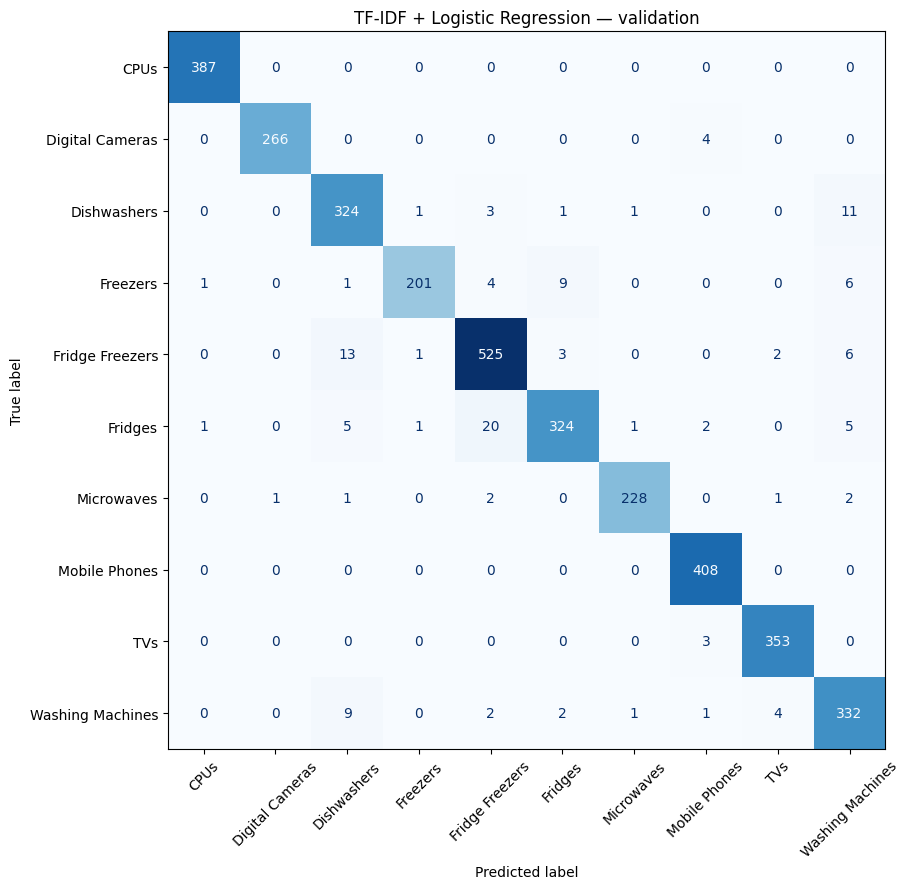

In [6]:
cm = confusion_matrix(y_val, pred_baseline, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
print('Wiersze: prawdziwa klasa. Kolumny: przewidziana klasa.')
print(cm_df.to_string())
cm_df.to_csv(RESULTS / 'tfidf_lr_confusion_matrix.csv', index_label='true_label')

fig, ax = plt.subplots(figsize=(12, 9))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
    ax=ax, xticks_rotation=45, values_format='d', cmap='Blues', colorbar=False
)
ax.set_title('TF-IDF + Logistic Regression — validation')
fig.tight_layout()
fig.savefig(RESULTS / 'tfidf_lr_confusion_matrix.png', dpi=140)
plt.show()

## 6. Pięć przykładów błędów

In [7]:
errors = val[['Product ID', 'Product Title', 'Category Label']].copy()
errors.columns = ['id', 'title', 'true_label']
errors['predicted_label'] = pred_baseline
errors = errors.loc[errors['true_label'] != errors['predicted_label']]

# Po jednym przykładzie z pięciu najczęstszych typów pomyłek.
error_counts = errors.groupby(['true_label', 'predicted_label']).size().sort_values(ascending=False)
selected = []
for true_class, predicted_class in error_counts.head(5).index:
    sample = errors.loc[
        (errors['true_label'] == true_class) &
        (errors['predicted_label'] == predicted_class)
    ].iloc[0]
    selected.append(sample)

error_examples = pd.DataFrame(selected).reset_index(drop=True)
print('Błędnych predykcji:', len(errors))
print(error_examples.to_string(index=False))
error_examples.to_csv(RESULTS / 'tfidf_lr_errors.csv', index=False)

Błędnych predykcji: 131
   id                       title       true_label  predicted_label
44351         liebherr ik 2764 20          Fridges  Fridge Freezers
37220 bosch kgn34nw3ag/kgn34nw3ag  Fridge Freezers      Dishwashers
27306     indesit dfg15b1/dfg15b1      Dishwashers Washing Machines
35244             liebherr gp2433         Freezers          Fridges
30173 bosch wan28201gb/wan28201gb Washing Machines      Dishwashers


## Analiza błędów

Przeanalizowano pięć błędnych predykcji modelu TF-IDF + Logistic Regression:

1. `liebherr ik 2764 20` — Fridges → Fridge Freezers
2. `bosch kgn34nw3ag/kgn34nw3ag` — Fridge Freezers → Dishwashers
3. `indesit dfg15b1/dfg15b1` — Dishwashers → Washing Machines
4. `liebherr gp2433` — Freezers → Fridges
5. `bosch wan28201gb/wan28201gb` — Washing Machines → Dishwashers

**Możliwa przyczyna:** Wszystkie te tytuły zawierają głównie markę i oznaczenie modelu, bez jednoznacznej informacji o rodzaju urządzenia. Model może mieć trudności z rozpoznaniem kategorii na podstawie samych kodów produktów. Dodatkowo część błędów dotyczy podobnych kategorii, np. lodówek i zamrażarek.

## 7. Zapis metryk i predykcji

In [9]:
def save_predictions(name, predictions):
    pd.DataFrame({
        'id': val['Product ID'].to_numpy(),
        'true_label': y_val.to_numpy(),
        'predicted_label': predictions,
    }).to_csv(RESULTS / f'{name}_predictions.csv', index=False)

save_predictions('dummy', pred_dummy)
save_predictions('tfidf_lr', pred_baseline)

hardware = f'CPU, {platform.system()} {platform.machine()}'
for name, metrics, seconds in [
    ('dummy', metrics_dummy, dummy_fit_seconds),
    ('tfidf_lr', metrics_baseline, baseline_fit_seconds),
]:
    data = {
        'split': 'validation',
        'seed': SEED,
        'metrics': metrics,
        'training_seconds': round(seconds, 4),
        'hardware': hardware,
        'python': sys.version.split()[0],
        'scikit_learn': sklearn.__version__,
    }
    (RESULTS / f'{name}_metrics.json').write_text(
        json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8'
    )
print('Zapisano wyniki do: results/validation/')

Zapisano wyniki do: results/validation/
